# Bài 03: Xử lý Ảnh Cổ điển — Bộ lọc, Phân ngưỡng, Hình thái học, Tách biên và Đường viền

## 1. Mục tiêu học tập
- Hiểu cơ chế tích chập không gian 2D (`2D Spatial Filtering / Convolution`) với nhân lọc (`kernel`).
- Thực hành và phân biệt **Tác dụng & Giới hạn** của:
  1. Làm mờ & Khử nhiễu: `Box Blur`, `Gaussian Filter`, `Median Filter` (đặc trị nhiễu muối tiêu).
  2. Làm sắc nét: `Sharpening Filter` (Unsharp Masking / Laplacian).
  3. Phân ngưỡng tách nền: `Global Thresholding`, `Otsu's Thresholding`, `Adaptive Thresholding`.
  4. Phép toán Hình thái học (`Morphology`): `Erosion` (co), `Dilation` (giãn), `Opening` (mở - xóa đốm nhiễu trắng), `Closing` (đóng - lấp lỗ thủng đen).
  5. Phát hiện biên (`Edge Detection`): đạo hàm bậc nhất `Sobel` và thuật toán đa bước `Canny`.
  6. Tìm đường viền (`Contour Detection`) để đếm, đo diện tích và đóng khung vật thể.

## 2. Kiến thức cần có
- Đã hoàn thành Bài 01 và Bài 02.

## 3. Thời gian học dự kiến
- Khoảng **2.5 giờ** (ước tính).

## 4. Bài toán thực tế đơn giản
Camera trên dây chuyền chụp ảnh các linh kiện hình học nhưng bị dính **nhiễu muối tiêu (salt-and-pepper noise)** do bụi cảm biến và **bóng đổ ánh sáng không đều** từ đèn chiếu nghiêng. Bạn cần khử nhiễu, tách mặt nạ nhị phân sạch và đếm chính xác số lượng linh kiện cùng diện tích của chúng.

## 5. Giải thích trực quan & Công thức Toán học
1. **Phép lọc tuyến tính 2D (2D Spatial Filtering)**:
   $$(I * K)(y, x) = \sum_{u=-a}^{a} \sum_{v=-b}^{b} I(y + u, x + v) \cdot K(u, v)$$
   - `Box Filter 3x3`: Trung bình cộng đều 9 pixel lân cận ($K_{uv} = 1/9$). Làm mờ nhanh nhưng làm nhòe biên mạnh.
   - `Gaussian Filter`: Trọng số giảm dần theo hàm chuông Gauss từ tâm ra ngoài ($G(u,v) \propto e^{-(u^2+v^2)/(2\sigma^2)}$). Khử nhiễu Gaussian mượt tự nhiên hơn Box Filter.
   - `Median Filter` (Bộ lọc phi tuyến): Thay pixel tâm bằng **trung vị (`median`)** của các pixel trong cửa sổ. Loại bỏ hoàn hảo các điểm nhiễu cực đại/cực tiểu (`0` hoặc `255`) mà **giữ nguyên độ sắc của cạnh**!
2. **Đạo hàm biên Sobel**:
   $$G_x = \begin{bmatrix} -1 & 0 & +1 \\ -2 & 0 & +2 \\ -1 & 0 & +1 \end{bmatrix} * I, \quad G_y = \begin{bmatrix} -1 & -2 & -1 \\ 0 & 0 & 0 \\ +1 & +2 & +1 \end{bmatrix} * I, \quad |\nabla I| = \sqrt{G_x^2 + G_y^2}$$

## 6. Thuật ngữ mới & Giải thích Keyword
| Keyword | Nghĩa tiếng Việt | Nhóm | Kiểu / Đơn vị | Giá trị, Ảnh hưởng khi Tăng/Giảm & Lưu ý |
|---|---|---|---|---|
| `ksize` (`kernel_size`) | Kích thước cửa sổ lọc | Xử lý ảnh | Số nguyên lẻ dương (`3, 5, 7...`) | Tăng `ksize` giúp làm mượt mạnh hơn nhưng làm mất các chi tiết nhỏ và tăng chi phí tính toán theo $K^2$. |
| `sigmaX` ($\sigma$) | Độ lệch chuẩn hàm Gauss | Xử lý ảnh | `float > 0` | Quyết định độ rộng của chuông Gauss trong `cv2.GaussianBlur`. Tăng $\sigma$ làm ảnh mờ nhiều hơn. |
| `THRESH_OTSU` | Thuật toán tự tìm ngưỡng Otsu | Xử lý ảnh | Cờ OpenCV | Tự động tìm ngưỡng $T^*$ cực đại hóa phương sai giữa 2 lớp sáng/tối (yêu cầu histogram có dạng 2 đỉnh – bimodal). |
| `Morphology Opening / Closing` | Phép Mở / Phép Đóng hình thái | Xử lý ảnh | `MORPH_OPEN`, `MORPH_CLOSE` | `Opening = Erosion -> Dilation` (xóa hạt nhiễu trắng nhỏ ngoài nền); `Closing = Dilation -> Erosion` (hàn gắn lỗ thủng nhỏ bên trong vật thể). |
| `Canny threshold1, threshold2` | Ngưỡng trễ dưới & trên của Canny | Xử lý ảnh | `float` (ví dụ `50, 150`) | Biên mạnh (`> threshold2`) được giữ chắc chắn; biên yếu nằm giữa `[threshold1, threshold2]` chỉ được giữ nếu nối liền với biên mạnh (Hysteresis). |


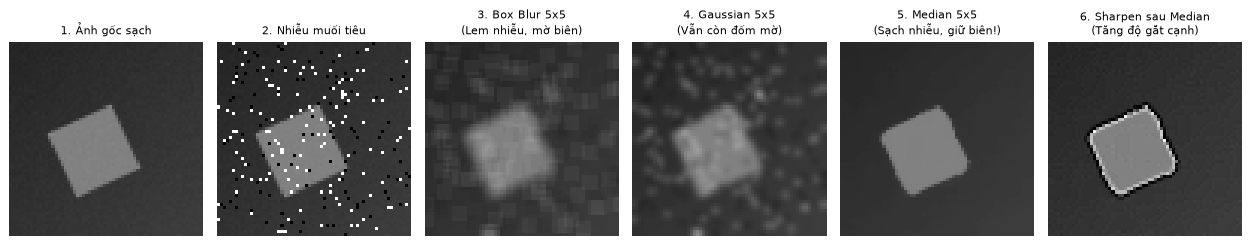

In [1]:
# Cell 1: Khử nhiễu & Làm sắc nét (Ảnh gốc -> Nhiễu -> Box / Gaussian / Median / Sharpen)
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if (project_root / "image_ai_learning").is_dir():
    project_root = project_root / "image_ai_learning"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from src.synthetic_data import generate_synthetic_shapes_dataset
from src.utils import set_seed

set_seed(42)
ds = generate_synthetic_shapes_dataset(num_samples=4, image_size=64, seed=42, noise_std=2.0)
clean_gray = cv2.cvtColor(ds["images"][1], cv2.COLOR_RGB2GRAY)

# Tạo ảnh dính nhiễu muối tiêu (Salt & Pepper 6% điểm ảnh)
rng = np.random.default_rng(42)
noisy_sp = clean_gray.copy()
rand_map = rng.random(clean_gray.shape)
noisy_sp[rand_map < 0.03] = 0
noisy_sp[rand_map > 0.97] = 255

# Áp dụng 3 bộ lọc làm mượt và 1 bộ lọc làm sắc nét
blur_box = cv2.blur(noisy_sp, ksize=(5, 5))
blur_gauss = cv2.GaussianBlur(noisy_sp, ksize=(5, 5), sigmaX=1.2)
blur_median = cv2.medianBlur(noisy_sp, ksize=5)

sharpen_kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32)
sharpened = cv2.filter2D(blur_median, ddepth=-1, kernel=sharpen_kernel)

fig, axes = plt.subplots(1, 6, figsize=(14, 2.6))
items = [
    (clean_gray, "1. Ảnh gốc sạch"),
    (noisy_sp, "2. Nhiễu muối tiêu"),
    (blur_box, "3. Box Blur 5x5\n(Lem nhiễu, mờ biên)"),
    (blur_gauss, "4. Gaussian 5x5\n(Vẫn còn đốm mờ)"),
    (blur_median, "5. Median 5x5\n(Sạch nhiễu, giữ biên!)"),
    (sharpened, "6. Sharpen sau Median\n(Tăng độ gắt cạnh)"),
]
for ax, (im, title) in zip(axes, items):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title, fontsize=8.8)
    ax.axis("off")
plt.tight_layout()
plt.show()


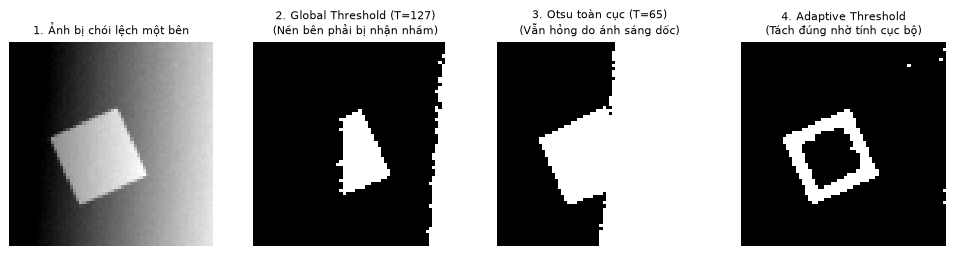

In [2]:
# Cell 2: Phân ngưỡng (Thresholding) trên ảnh có bóng đổ không đều: Global vs Otsu vs Adaptive
# Tạo ảnh có vật thể kèm độ dốc ánh sáng mạnh từ trái sang phải (mô phỏng đèn chiếu lệch)
h, w = clean_gray.shape
illumination_ramp = np.tile(np.linspace(-70, 90, w, dtype=np.float32), (h, 1))
uneven_img = np.clip(clean_gray.astype(np.float32) + illumination_ramp, 0, 255).astype(np.uint8)

# 1. Ngưỡng cố định (Global = 127)
_, th_global = cv2.threshold(uneven_img, 127, 255, cv2.THRESH_BINARY)
# 2. Ngưỡng tự động toàn cục Otsu
otsu_val, th_otsu = cv2.threshold(uneven_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
# 3. Ngưỡng thích nghi cục bộ (Adaptive Gaussian Thresholding)
th_adaptive = cv2.adaptiveThreshold(
    uneven_img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, blockSize=15, C=-5
)

fig, axes = plt.subplots(1, 4, figsize=(11, 2.8))
for ax, im, title in zip(
    axes,
    [uneven_img, th_global, th_otsu, th_adaptive],
    [
        "1. Ảnh bị chói lệch một bên",
        "2. Global Threshold (T=127)\n(Nền bên phải bị nhận nhầm)",
        f"3. Otsu toàn cục (T={otsu_val:.0f})\n(Vẫn hỏng do ánh sáng dốc)",
        "4. Adaptive Threshold\n(Tách đúng nhờ tính cục bộ)",
    ],
):
    ax.imshow(im, cmap="gray")
    ax.set_title(title, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()


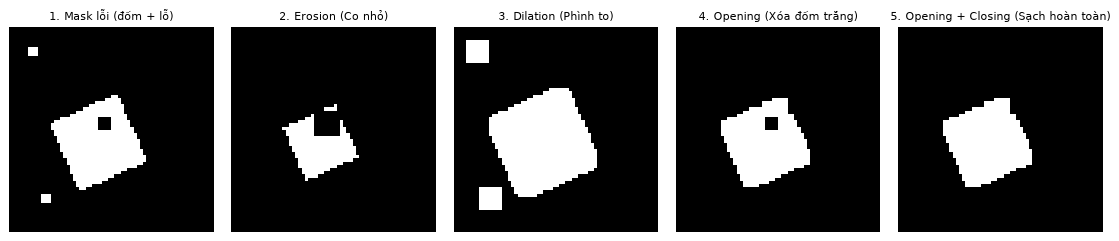

In [3]:
# Cell 3: Hình thái học (Morphology) — Erosion, Dilation, Opening (xóa đốm trắng), Closing (lấp lỗ đen)
# Tạo mặt nạ nhị phân có cả đốm nhiễu trắng ngoài nền và lỗ thủng đen bên trong vật thể
_, base_mask = cv2.threshold(clean_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
corrupted_mask = base_mask.copy()
corrupted_mask[6:9, 6:9] = 255     # Đốm nhiễu trắng ngoài nền
corrupted_mask[52:55, 10:13] = 255 # Đốm nhiễu trắng ngoài nền
corrupted_mask[28:32, 28:32] = 0   # Lỗ thủng đen giữa vật thể

kernel_morph = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
eroded = cv2.erode(corrupted_mask, kernel_morph, iterations=1)
dilated = cv2.dilate(corrupted_mask, kernel_morph, iterations=1)
opened = cv2.morphologyEx(corrupted_mask, cv2.MORPH_OPEN, kernel_morph)
closed_after_open = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel_morph)

fig, axes = plt.subplots(1, 5, figsize=(12.5, 2.6))
for ax, im, title in zip(
    axes,
    [corrupted_mask, eroded, dilated, opened, closed_after_open],
    [
        "1. Mask lỗi (đốm + lỗ)",
        "2. Erosion (Co nhỏ)",
        "3. Dilation (Phình to)",
        "4. Opening (Xóa đốm trắng)",
        "5. Opening + Closing (Sạch hoàn toàn)",
    ],
):
    ax.imshow(im, cmap="gray")
    ax.set_title(title, fontsize=8.8)
    ax.axis("off")
plt.tight_layout()
plt.show()


Tổng số vật thể phát hiện qua Contour: 3
  - Vật thể #1: bbox=(x=14, y=24, w=33, h=33), Diện tích=752.0 px², Chu vi=104.6 px
  - Vật thể #2: bbox=(x=68, y=22, w=37, h=37), Diện tích=1296.0 px², Chu vi=144.0 px
  - Vật thể #3: bbox=(x=118, y=20, w=35, h=39), Diện tích=647.0 px², Chu vi=124.1 px


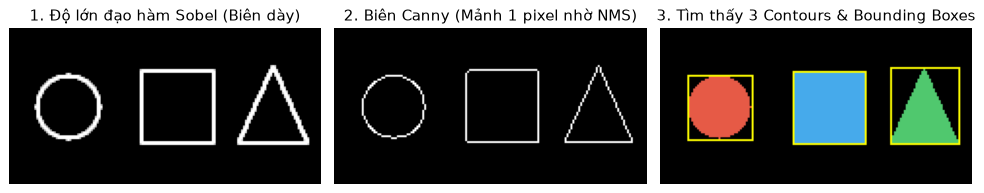

In [4]:
# Cell 4: Phát hiện biên (Sobel vs Canny) và Tìm đường viền (Contours) để đếm & đo diện tích
# Tạo ảnh chứa 3 vật thể tách rời để thực hành đếm bằng Contour
canvas_multi = np.zeros((80, 160, 3), dtype=np.uint8)
cv2.circle(canvas_multi, (30, 40), 16, (230, 90, 70), -1)
cv2.rectangle(canvas_multi, (68, 22), (104, 58), (70, 170, 235), -1)
pts_tri = np.array([[135, 20], [118, 58], [152, 58]], dtype=np.int32)
cv2.fillConvexPoly(canvas_multi, pts_tri, (80, 200, 110))
gray_multi = cv2.cvtColor(canvas_multi, cv2.COLOR_RGB2GRAY)

# Tính đạo hàm biên Sobel và biên Canny
gx = cv2.Sobel(gray_multi, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(gray_multi, cv2.CV_32F, 0, 1, ksize=3)
sobel_mag = np.clip(np.hypot(gx, gy), 0, 255).astype(np.uint8)
canny_edges = cv2.Canny(gray_multi, threshold1=50, threshold2=150)

# Tìm Contours trên ảnh nhị phân
_, bin_multi = cv2.threshold(gray_multi, 30, 255, cv2.THRESH_BINARY)
contours, _ = cv2.findContours(bin_multi, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

vis_contours = canvas_multi.copy()
print(f"Tổng số vật thể phát hiện qua Contour: {len(contours)}")
for idx, cnt in enumerate(contours):
    area = cv2.contourArea(cnt)
    perimeter = cv2.arcLength(cnt, closed=True)
    x, y, bw, bh = cv2.boundingRect(cnt)
    cv2.rectangle(vis_contours, (x, y), (x + bw, y + bh), (255, 255, 0), 1)
    print(f"  - Vật thể #{idx+1}: bbox=(x={x}, y={y}, w={bw}, h={bh}), Diện tích={area:.1f} px², Chu vi={perimeter:.1f} px")

fig, axes = plt.subplots(1, 3, figsize=(11, 2.8))
axes[0].imshow(sobel_mag, cmap="gray")
axes[0].set_title("1. Độ lớn đạo hàm Sobel (Biên dày)")
axes[1].imshow(canny_edges, cmap="gray")
axes[1].set_title("2. Biên Canny (Mảnh 1 pixel nhờ NMS)")
axes[2].imshow(vis_contours)
axes[2].set_title(f"3. Tìm thấy {len(contours)} Contours & Bounding Boxes")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 11. Nhận xét cách đọc kết quả & Phân tích Giới hạn
- **Box/Gaussian vs Median (Cell 1)**: Với nhiễu xung (muối tiêu `0` và `255`), `Box` và `Gaussian` lấy trung bình cộng nên kéo giá trị nhiễu lan ra xung quanh làm mờ biên. Ngược lại, `Median` sắp xếp các điểm trong cửa sổ và lấy điểm chính giữa nên loại bỏ triệt để điểm cực đoan. Tuy nhiên, nếu mật độ nhiễu `> 40%` hoặc cần giữ kết cấu hạt mịn, `Median` với cửa sổ lớn sẽ làm bệt chi tiết.
- **Otsu vs Adaptive Threshold (Cell 2)**: `Otsu` tìm một ngưỡng duy nhất cho toàn bức ảnh nên thất bại khi ánh sáng chênh lệch giữa hai nửa ảnh. `Adaptive Threshold` tính ngưỡng riêng cho từng vùng lân cận `blockSize x blockSize`, nhưng có giới hạn là nhạy cảm với nhiễu ở các mảng nền phẳng rộng nếu hằng số `C` chọn quá nhỏ.
- **Khi nào Xử lý ảnh cổ điển là ĐỦ, và khi nào cần Học máy (ML/DL)?**
  - Nếu điều kiện chiếu sáng cố định trong buồng kín, vật thể tách biệt rõ với nền đồng màu → Chuỗi `Median -> Threshold -> Morphology -> Contour` (Cell 4) chạy trong `< 1 ms` trên CPU và đạt độ chính xác tuyệt vời mà không cần thu thập hàng nghìn ảnh để huấn luyện AI!
  - Nhưng nếu vật thể chồng lấp nhau, nền lộn xộn ngoài trời, hoặc các lớp chỉ khác nhau ở ngữ nghĩa phức tạp (mèo vs chó) → Các ngưỡng cố định hoàn toàn bất lực, lúc đó ta bắt buộc phải chuyển sang **Machine Learning / Deep Learning** từ Bài 04 trở đi.

## 13. Lỗi thường gặp và cách sửa
1. **Truyền `ksize` chẵn vào `GaussianBlur` hoặc `medianBlur`**: OpenCV yêu cầu `ksize` phải là **số nguyên dương lẻ** (`3, 5, 7...`) để cửa sổ có đúng 1 pixel tâm đối xứng.
2. **Dùng `cv2.Sobel(..., cv2.CV_8U)` làm mất toàn bộ đạo hàm âm**: Khi chuyển từ vùng sáng sang vùng tối, đạo hàm mang dấu âm. Nếu để `ddepth=cv2.CV_8U`, mọi số âm bị cắt thành `0` (mất một nửa số cạnh!). Hãy luôn tính Sobel với `cv2.CV_32F` rồi lấy trị tuyệt đối hoặc `np.hypot(gx, gy)`.

## 14. Bài tập tự làm
- **Cơ bản**: Thử thay đổi `ksize` của `cv2.GaussianBlur` qua `[3, 7, 13]` và tính độ lớn biên Sobel trung bình của ảnh sau làm mờ để chứng minh làm mờ càng mạnh thì độ dốc biên càng giảm.
- **Trung cấp**: Tính chỉ số **Độ tròn (`Circularity`)** của mỗi contour theo công thức $C = \frac{4 \pi \times \text{Area}}{\text{Perimeter}^2}$ (hình tròn lý tưởng có $C \approx 1.0$, hình vuông/tam giác có $C$ nhỏ hơn) để tự động phân biệt hình tròn với hình vuông và tam giác ở Cell 4!
- **Nâng cao**: Viết hàm tự động chọn ngưỡng Canny dựa trên trung vị cường độ sáng $v = \text{median}(I)$: `lower = max(0, 0.67 * v)`, `upper = min(255, 1.33 * v)`.

## 15. Gợi ý và Lời giải


In [5]:
# Cell 5: Lời giải hoàn chỉnh cho bài tập Bài 03
# 1. Cơ bản: Ảnh hưởng của ksize làm mờ lên độ mạnh biên Sobel
for k in [3, 7, 13]:
    g_blur = cv2.GaussianBlur(clean_gray, (k, k), sigmaX=0)
    sx = cv2.Sobel(g_blur, cv2.CV_32F, 1, 0, ksize=3)
    sy = cv2.Sobel(g_blur, cv2.CV_32F, 0, 1, ksize=3)
    print(f"[Cơ bản] Gaussian ksize={k:2d} -> Độ lớn biên Sobel trung bình: {np.hypot(sx, sy).mean():.2f}")

# 2. Trung cấp: Phân loại hình dạng bằng độ tròn (Circularity) từ Contour
for idx, cnt in enumerate(contours):
    area = cv2.contourArea(cnt)
    peri = cv2.arcLength(cnt, closed=True)
    circularity = (4.0 * np.pi * area) / (peri ** 2 + 1e-6)
    x, _, _, _ = cv2.boundingRect(cnt)
    print(f"[Trung cấp] Contour tại x={x:3d}: Circularity = {circularity:.3f}")

# 3. Nâng cao: Auto-Canny dựa trên median
def auto_canny(gray_img: np.ndarray, sigma: float = 0.33) -> np.ndarray:
    v = float(np.median(gray_img))
    lower = int(max(0, (1.0 - sigma) * v))
    upper = int(min(255, (1.0 + sigma) * v))
    return cv2.Canny(gray_img, lower, upper)

edges_auto = auto_canny(clean_gray)
print("[Nâng cao] Số pixel biên phát hiện bởi Auto-Canny:", int((edges_auto > 0).sum()))


[Cơ bản] Gaussian ksize= 3 -> Độ lớn biên Sobel trung bình: 17.05
[Cơ bản] Gaussian ksize= 7 -> Độ lớn biên Sobel trung bình: 15.51
[Cơ bản] Gaussian ksize=13 -> Độ lớn biên Sobel trung bình: 14.63
[Trung cấp] Contour tại x= 14: Circularity = 0.864
[Trung cấp] Contour tại x= 68: Circularity = 0.785
[Trung cấp] Contour tại x=118: Circularity = 0.528
[Nâng cao] Số pixel biên phát hiện bởi Auto-Canny: 88


## 16. Tóm tắt & Điều kiện chuyển bài tiếp theo
- [x] Đã nắm vững bộ công cụ Xử lý ảnh cổ điển (`Filter`, `Threshold`, `Morphology`, `Sobel/Canny`, `Contour`).
- [x] Hiểu rõ khi nào xử lý ảnh cổ điển là đủ và khi nào cần chuyển sang mô hình học từ dữ liệu.
- [x] Sẵn sàng bước vào **Giai đoạn B — Bài 04: `04_math_and_ml_foundations.ipynb`**.

## 17. Nguồn tham khảo
- Canny, J. (1986), *A Computational Approach to Edge Detection*, IEEE TPAMI.
- Otsu, N. (1979), *A Threshold Selection Method from Gray-Level Histograms*, IEEE Trans. SMC.
